# Transformer-Based Spam Detection Using Contextual Language Models
**CSEC 6 — Natural Language Processing**  
Camarines Sur Polytechnic Colleges

---

This notebook implements the full pipeline described in the paper:
1. Data loading & preprocessing
2. Tokenization (subword / WordPiece)
3. Fine-tuning BERT, RoBERTa, DistilBERT
4. Class imbalance handling (weighted loss + stratified sampling)
5. Evaluation — macro F1, precision, recall, ROC-AUC
6. Classical baselines (TF-IDF + Naive Bayes / SVM / Logistic Regression)
7. Ablation experiments
8. Cross-corpus generalization

## Install Dependencies
> **Why:** The paper uses HuggingFace Transformers for BERT/RoBERTa/DistilBERT pretrained weights, scikit-learn for classical baselines, and standard ML libraries for evaluation.

In [1]:
! pip install transformers datasets scikit-learn torch pandas numpy accelerate tqdm -q

## Cell 2 Imports
> **Why:** We import everything needed for the full pipeline. `AutoTokenizer` and `AutoModelForSequenceClassification` let us swap between BERT, RoBERTa, and DistilBERT with one line change — matching the paper's unified fine-tuning pipeline across all three architectures.

In [ ]:
import subprocess
import os

# Auto-select best GPU before PyTorch initializes
def pick_best_gpu():
    result = subprocess.run(
        ['nvidia-smi', '--query-gpu=index,utilization.gpu,memory.used',
         '--format=csv,noheader,nounits'],
        capture_output=True, text=True
    )
    best_gpu = None
    best_score = float('inf')
    for line in result.stdout.strip().split('\n'):
        idx, util, mem = [x.strip() for x in line.split(',')]
        score = int(util) + int(mem) * 0.001  # weighted: util + memory pressure
        if score < best_score:
            best_score = score
            best_gpu = idx
    return best_gpu

best = pick_best_gpu()
os.environ['CUDA_VISIBLE_DEVICES'] = best
print(f'Auto-selected GPU {best}')

# Imports
import re
import json
import warnings
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torch.nn import CrossEntropyLoss
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    AutoConfig,
    get_linear_schedule_with_warmup,
)
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    roc_auc_score, accuracy_score, confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')

# Device setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB')
    print(f'Physical GPU index: {best}')

Auto-selected GPU 1
Device: cuda
GPU: NVIDIA RTX A5000
VRAM: 23.7 GB
Physical GPU index: 1


## Cell 3 Configuration
> **Why:** The paper specifies exact hyperparameters:
> - Learning rate: 2×10⁻⁵ to 5×10⁻⁵ (we use 2e-5)
> - Max epochs: 5 with early stopping on validation F1
> - Dropout: p=0.1 on the [CLS] representation
> - Warmup: first 10% of training steps
> - Split: 70% train / 15% validation / 15% test (stratified)

In [ ]:
# Model options (swap MODEL_NAME to change architecture)
MODEL_OPTIONS = {
    'distilbert': 'distilbert-base-uncased',   # lightweight, fast
    'bert':       'bert-base-uncased',         # full BERT-base
    'roberta':    'roberta-base',              # RoBERTa variant
}

# Change this line to switch models
ACTIVE_MODEL = 'bert'   # 'bert' | 'roberta' | 'distilbert'
MODEL_NAME   = MODEL_OPTIONS[ACTIVE_MODEL]

# Hyperparameters (from paper Section 4)
MAX_LEN      = 512     # paper: sequences truncated to model max length
BATCH_SIZE   = 16
EPOCHS       = 5       # paper: max 5 epochs
LR           = 2e-5    # paper: 2x10^-5 to 5x10^-5
WARMUP_RATIO = 0.10    # paper: warmup first 10% of steps
DROPOUT      = 0.1     # paper: dropout p=0.1 on [CLS] representation

# Dataset paths
# Expected columns: text + label (or convertible aliases)
DATASET_PATHS = {
    'enron':        'data/enron.csv',
    'spamassassin': 'data/spam_assassin.csv',
    'lingspam':     'data/lingspam.csv',
}

# Default to a labeled dataset available in this workspace
ACTIVE_DATASET = 'spamassassin'   # 'enron' | 'spamassassin' | 'lingspam'

print(f'Model   : {MODEL_NAME}')
print(f'Dataset : {ACTIVE_DATASET}')
print(f'Max len : {MAX_LEN} tokens')

Model   : bert-base-uncased
Dataset : spamassassin
Max len : 512 tokens


## Cell 4 Load Dataset
> **Why:** The paper uses three benchmark datasets — Enron (~33,700 emails), SpamAssassin (with easy/hard ham subcategories), and LingSpam (academic mailing list). Each has different spam typologies, which is exactly why three datasets are used — to test cross-domain generalizability.

In [4]:
def load_dataset(path):
    """
    Load CSV dataset with flexible schema and normalize to columns: text, label.
    label convention: 0=ham, 1=spam
    """
    df = pd.read_csv(path)
    df.columns = [c.strip().lower() for c in df.columns]

    # Rename message → text if needed (Enron uses 'message')
    if 'message' in df.columns and 'text' not in df.columns:
        df.rename(columns={'message': 'text'}, inplace=True)

    # Normalize possible text/label aliases
    rename_map = {}
    text_aliases  = {'message', 'body', 'content', 'email', 'text'}
    label_aliases = {'label', 'spam', 'class', 'category', 'target', 'spam/ham'}

    for col in df.columns:
        if col in text_aliases and col != 'text':
            rename_map[col] = 'text'
        elif col in label_aliases:
            rename_map[col] = 'label'

    df.rename(columns=rename_map, inplace=True)

    if 'text' not in df.columns:
        raise ValueError(
            f"No text column found in {path}. Columns found: {list(df.columns)}"
        )

    if 'label' not in df.columns:
        # Try to infer labels from path-like file column (common in some corpora)
        if 'file' in df.columns:
            file_series = df['file'].astype(str).str.lower()
            has_signal = file_series.str.contains(r'spam|ham', regex=True).any()
            if has_signal:
                df['label'] = file_series.str.contains(r'spam', regex=True).astype(int)
            else:
                raise ValueError(
                    f"No label column found in {path}. Columns found: {list(df.columns)}. "
                    "This dataset appears unlabeled for spam detection."
                )
        else:
            raise ValueError(
                f"No label column found in {path}. Columns found: {list(df.columns)}"
            )

    # Always normalize labels — handles string types across all datasets
    label_map = {
        'spam': 1, 'junk': 1, '1': 1,
        'ham': 0, 'not spam': 0, 'notspam': 0,
        'legit': 0, 'legitimate': 0, '0': 0,
    }

    # Try mapping first — handles Enron (spam/ham strings)
    mapped = df['label'].astype(str).str.strip().str.lower().map(label_map)

    if mapped.notna().all():
        # All values successfully mapped from strings
        df['label'] = mapped
    else:
        # Already numeric (SpamAssassin, LingSpam) — convert directly
        df['label'] = pd.to_numeric(df['label'], errors='coerce')

    df = df[['text', 'label']].dropna()
    df['text']  = df['text'].astype(str)
    df['label'] = df['label'].astype(int)

    unique_labels = set(df['label'].unique().tolist())
    if not unique_labels.issubset({0, 1}):
        raise ValueError(f"Labels must be binary 0/1, got: {sorted(unique_labels)}")
    if len(unique_labels) < 2:
        raise ValueError("Dataset must contain both ham(0) and spam(1) classes.")

    return df

df = load_dataset(DATASET_PATHS[ACTIVE_DATASET])

print(f'Total samples : {len(df)}')
print(f'Spam (1)      : {df["label"].sum()} ({df["label"].mean():.1%})')
print(f'Ham  (0)      : {(df["label"]==0).sum()} ({(df["label"]==0).mean():.1%})')
df.head(3)

Total samples : 5796
Spam (1)      : 1896 (32.7%)
Ham  (0)      : 3900 (67.3%)


,text,label
0,From ilug-admin@linux.ie Mon Jul 29 11:28:02 2...,0
1,From gort44@excite.com Mon Jun 24 17:54:21 200...,1
2,From fork-admin@xent.com Mon Jul 29 11:39:57 2...,1


## Cell 5 Text Preprocessing
> **Why:** The paper explicitly describes this preprocessing pipeline in Section 3:
> 1. Strip HTML markup to remove formatting artifacts
> 2. Remove email headers (From, To, Subject, routing) — prevents model from learning spurious header-based cues
> 3. Unicode-normalized lowercase
> 4. Remove boilerplate footers and legal disclaimers

In [5]:
def preprocess_text(text):
    """
    Preprocessing pipeline from paper Section 3:
    1. Strip HTML markup
    2. Remove email headers
    3. Unicode lowercase normalization
    4. Remove boilerplate footers
    """
    # Step 1 — Strip HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)

    # Step 2 — Remove email header lines (From:, To:, Subject:, etc.)
    text = re.sub(r'^(From|To|Subject|Date|Cc|Reply-To|Message-ID|'  
                  r'Return-Path|Received|MIME-Version|Content-Type|'  
                  r'Content-Transfer-Encoding|X-[\w-]+):.*$',
                  '', text, flags=re.MULTILINE | re.IGNORECASE)

    # Step 3 — Lowercase + unicode normalization
    text = text.lower()

    # Step 4 — Remove boilerplate footers / legal disclaimers
    text = re.sub(
        r'(this email is confidential|unsubscribe|legal disclaimer'
        r'|this message contains|privileged communication).*',
        '', text, flags=re.IGNORECASE | re.DOTALL
    )

    # Clean up extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['text'] = df['text'].apply(preprocess_text)

# Remove empty rows after preprocessing
df = df[df['text'].str.len() > 10].reset_index(drop=True)
print(f'After preprocessing: {len(df)} samples')
print('\nSample:')
print(df['text'].iloc[0][:300])

After preprocessing: 5393 samples

Sample:
from ilug-admin@linux.ie mon jul 29 11:28:02 2002 return-path: delivered-to: yyyy@localhost.netnoteinc.com received: from localhost (localhost [127.0.0.1]) by phobos.labs.netnoteinc.com (postfix) with esmtp id a13d94414f for ; mon, 29 jul 2002 06:25:11 -0400 (edt) received: from phobos [127.0.0.1] b


## Cell 6 Stratified Train/Validation/Test Split
> **Why:** Paper Section 3 specifies: *"Training (70%), validation (15%), and test (15%) subsets will be separated using stratified sampling to ensure the proportions of classes among all of them are the same."* This is critical because spam datasets are imbalanced — stratification prevents the test set from being accidentally all-ham.

In [6]:
texts  = df['text'].tolist()
labels = df['label'].tolist()

# 70 / 30 split first, then split the 30 into 15/15
train_texts, tmp_texts, train_labels, tmp_labels = train_test_split(
    texts, labels,
    test_size=0.30,
    stratify=labels,   # ← paper: stratified sampling
    random_state=42
)

val_texts, test_texts, val_labels, test_labels = train_test_split(
    tmp_texts, tmp_labels,
    test_size=0.50,
    stratify=tmp_labels,
    random_state=42
)

print(f'Train : {len(train_texts):>6} samples  |  spam={sum(train_labels):>5}  ham={len(train_labels)-sum(train_labels):>5}')
print(f'Val   : {len(val_texts):>6} samples  |  spam={sum(val_labels):>5}  ham={len(val_labels)-sum(val_labels):>5}')
print(f'Test  : {len(test_texts):>6} samples  |  spam={sum(test_labels):>5}  ham={len(test_labels)-sum(test_labels):>5}')

Train :   3775 samples  |  spam= 1148  ham= 2627
Val   :    809 samples  |  spam=  246  ham=  563
Test  :    809 samples  |  spam=  246  ham=  563


## Cell 7 Subword Tokenization
> **Why:** Paper Section 3 says: *"The WordPiece tokenizer of a model architecture is used to tokenize the text. This tokenization scheme breaks morphologically complex or out-of-vocabulary tokens into known subword units, effectively alleviating the OOV problem."*  
> The paper also mentions using a **sliding-window** truncation strategy retaining start and end of messages, since spam signals often appear there.

In [7]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class SpamDataset(Dataset):
    """
    PyTorch Dataset with subword tokenization.
    Truncation strategy: keeps start + end of long messages (paper Section 3).
    """
    def __init__(self, texts, labels, tokenizer, max_len=MAX_LEN):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def _truncate_keep_edges(self, text):
        # Paper Section 3: sliding-window truncation retains start + end
        # because spam signals are often located at both ends of a message.
        tokens = self.tokenizer.encode(
            text,
            add_special_tokens=False,
            truncation=False,
        )
        max_tokens = self.max_len - 2  # reserve slots for [CLS] and [SEP]
        if len(tokens) <= max_tokens:
            return text
        # Keep first half + last half
        half = max_tokens // 2
        tokens = tokens[:half] + tokens[-(max_tokens - half):]
        return self.tokenizer.decode(tokens, skip_special_tokens=True)

    def __getitem__(self, idx):
        text = self._truncate_keep_edges(self.texts[idx])
        enc = self.tokenizer(
            text,
            max_length=self.max_len,
            padding='max_length',
            truncation=True,   # safety net in case decode adds tokens
            return_tensors='pt',
        )
        return {
            'input_ids':      enc['input_ids'].squeeze(0),
            'attention_mask': enc['attention_mask'].squeeze(0),
            'labels':         torch.tensor(self.labels[idx], dtype=torch.long),
        }

train_ds = SpamDataset(train_texts, train_labels, tokenizer)
val_ds   = SpamDataset(val_texts,   val_labels,   tokenizer)
test_ds  = SpamDataset(test_texts,  test_labels,  tokenizer)

# FIX 1 (Paper Section 4): Use shuffle=True instead of WeightedRandomSampler.
# The paper describes stratified mini-batch sampling to preserve natural class
# proportions per batch — NOT forced 50/50 oversampling via WeightedRandomSampler.
# Using both WeightedRandomSampler AND weighted loss (Cell 8) double-compensates
# for class imbalance, causing the model to aggressively over-predict SPAM on
# borderline messages (ham flagged as spam). The weighted cross-entropy loss
# in Cell 8 is the primary and sufficient imbalance mechanism per the paper.
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False)

print(f'Tokenizer      : {MODEL_NAME}')
print(f'Train batches  : {len(train_loader)}')
print(f'Val batches    : {len(val_loader)}')
print(f'Test batches   : {len(test_loader)}')

sample = tokenizer(train_texts[0], max_length=20, truncation=True)
print(f'\nSample tokens  : {tokenizer.convert_ids_to_tokens(sample["input_ids"])}')


Tokenizer      : bert-base-uncased
Train batches  : 236
Val batches    : 51
Test batches   : 51

Sample tokens  : ['[CLS]', 'from', 'cash', '##in', '@', 'my', '##mail', '.', 'gr', 'sun', 'sep', '22', '14', ':', '13', ':', '18', '2002', 'return', '[SEP]']


## Cell 8 Class Imbalance: Weighted Cross-Entropy Loss
> **Why:** Paper Section 4: *"Weights of classes which are inversely proportional to the class frequencies will be included into the cross-entropy loss function."* This is one of the paper's key contributions for handling the ham-heavy imbalance in spam datasets. The weight of each class = 1 / (class_frequency / total).

In [8]:
import numpy as np

def compute_class_weights(labels):
    """
    Paper Section 4:
    w_i = 1 / (count_i / total)
    Inversely proportional to class frequency.
    """
    counts  = np.bincount(labels)
    total   = sum(counts)
    weights = torch.tensor([total / c for c in counts], dtype=torch.float)
    return weights

class_weights = compute_class_weights(train_labels)
print(f'Class weights — Ham: {class_weights[0]:.4f}  |  Spam: {class_weights[1]:.4f}')
print('(Higher weight = rarer class gets penalized more when misclassified)')

# Weighted loss function
loss_fn = CrossEntropyLoss(weight=class_weights.to(device))

Class weights — Ham: 1.4370  |  Spam: 3.2883
(Higher weight = rarer class gets penalized more when misclassified)


## Cell 9 Load Pretrained Transformer Model
> **Why:** Paper Section 4 describes the BERT-BASE architecture: *"12 Transformer encoder layers, 12 attention heads, hidden size of 768, ~110M parameters."* The [CLS] token representation feeds into a single linear + softmax classification head. Models are loaded from HuggingFace Model Hub with dropout p=0.1.

In [9]:
from transformers import AutoConfig

# Load config first, then set dropout based on model type
# Fix: each model family uses different dropout param names
config = AutoConfig.from_pretrained(MODEL_NAME, num_labels=2)

if 'distilbert' in MODEL_NAME:
    config.seq_classif_dropout = DROPOUT   # DistilBERT classifier dropout
    config.dropout = DROPOUT               # DistilBERT attention dropout
elif 'roberta' in MODEL_NAME:
    config.hidden_dropout_prob = DROPOUT
    config.attention_probs_dropout_prob = DROPOUT
else:  # bert
    config.hidden_dropout_prob = DROPOUT
    config.attention_probs_dropout_prob = DROPOUT

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    config=config,
)
model.to(device)

# Count parameters
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Model          : {MODEL_NAME}')
print(f'Total params   : {total_params:,}')
print(f'Trainable      : {trainable_params:,}')


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model          : bert-base-uncased
Total params   : 109,483,778
Trainable      : 109,483,778


## Cell 10 Optimizer & Learning Rate Scheduler
> **Why:** Paper Section 4: *"Fine-tuning will use a learning rate of 2×10⁻⁵–5×10⁻⁵ with warmup linear behavior during the first 10% of training steps, then linear decrease to zero."* This warmup-then-decay schedule is standard for BERT fine-tuning and prevents the pretrained weights from being destroyed early in training.

In [10]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=0.01
)

total_steps   = len(train_loader) * EPOCHS
warmup_steps  = int(WARMUP_RATIO * total_steps)  # paper: first 10% of steps

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps,
)

print(f'Total steps    : {total_steps}')
print(f'Warmup steps   : {warmup_steps}  ({WARMUP_RATIO:.0%} of total)')
print(f'Optimizer      : AdamW  lr={LR}  weight_decay=0.01')

Total steps    : 1180
Warmup steps   : 118  (10% of total)
Optimizer      : AdamW  lr=2e-05  weight_decay=0.01


## Cell 11 Evaluation Function
> **Why:** Paper Section 5 defines the evaluation metrics:  
> - **Macro-averaged F1** — primary metric; balances precision & recall without favoring majority class  
> - **Precision** — how many flagged spam are actually spam (minimize false positives)  
> - **Recall** — how many actual spam are caught (minimize false negatives)  
> - **ROC-AUC** — discriminative strength across all classification thresholds  
> Accuracy is reported but acknowledged as misleading under class imbalance.

In [11]:
def evaluate(model, loader, device):
    """
    Compute paper metrics: accuracy, macro F1, macro precision/recall, ROC-AUC.
    Also returns class-specific recall/precision for spam-class analysis.
    """
    model.eval()
    all_preds, all_labels, all_probs = [], [], []

    with torch.no_grad():
        for batch in loader:
            ids = batch['input_ids'].to(device)
            mask = batch['attention_mask'].to(device)
            lbls = batch['labels']

            out = model(input_ids=ids, attention_mask=mask)
            probs = torch.softmax(out.logits, dim=1)[:, 1].cpu().numpy()
            preds = out.logits.argmax(dim=1).cpu().numpy()

            all_preds.extend(preds.tolist())
            all_labels.extend(lbls.numpy().tolist())
            all_probs.extend(probs.tolist())

    # Handle edge case where only one class appears in evaluation labels
    if len(set(all_labels)) > 1:
        roc_auc = round(roc_auc_score(all_labels, all_probs), 4)
    else:
        roc_auc = float('nan')

    precision_per_class = precision_score(all_labels, all_preds, average=None, labels=[0, 1], zero_division=0)
    recall_per_class = recall_score(all_labels, all_preds, average=None, labels=[0, 1], zero_division=0)

    return {
        'accuracy': round(accuracy_score(all_labels, all_preds), 4),
        'f1_macro': round(f1_score(all_labels, all_preds, average='macro', zero_division=0), 4),
        'precision': round(precision_score(all_labels, all_preds, average='macro', zero_division=0), 4),
        'recall': round(recall_score(all_labels, all_preds, average='macro', zero_division=0), 4),
        'roc_auc': roc_auc,
        'ham_precision': round(float(precision_per_class[0]), 4),
        'spam_precision': round(float(precision_per_class[1]), 4),
        'ham_recall': round(float(recall_per_class[0]), 4),
        'spam_recall': round(float(recall_per_class[1]), 4),
        'preds': all_preds,
        'labels': all_labels,
        'probs': all_probs,
    }

print('Evaluation function ready.')
print('Metrics: accuracy, f1_macro, precision, recall, roc_auc, spam_recall')

Evaluation function ready.
Metrics: accuracy, f1_macro, precision, recall, roc_auc, spam_recall


## Cell 12 Training Loop
> **Why:** Implements the full fine-tuning pipeline from paper Section 4:
> - End-to-end fine-tuning (all encoder layers trainable)
> - Weighted cross-entropy loss (handles class imbalance)
> - Gradient clipping (norm=1.0) for training stability
> - Early stopping on validation F1 (patience=2)
> - Mixed precision (FP16) when GPU is available
> - Best model checkpoint saved

In [12]:
from torch.amp import GradScaler, autocast  # Fix: updated import path

save_dir    = f'models/{ACTIVE_MODEL}_{ACTIVE_DATASET}'
os.makedirs(save_dir, exist_ok=True)

scaler      = GradScaler('cuda', enabled=torch.cuda.is_available())  # Fix: device arg required
best_f1     = 0.0
best_epoch  = 0
history     = []

for epoch in range(1, EPOCHS + 1):
    # Training phase
    model.train()
    total_loss = 0

    for batch in tqdm(train_loader, desc=f'Epoch {epoch}/{EPOCHS} [train]'):
        ids   = batch['input_ids'].to(device)
        mask  = batch['attention_mask'].to(device)
        lbls  = batch['labels'].to(device)

        optimizer.zero_grad()

        with autocast('cuda', enabled=torch.cuda.is_available()):  # Fix: device arg required
            out  = model(input_ids=ids, attention_mask=mask)
            loss = loss_fn(out.logits, lbls)               # weighted cross-entropy

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # gradient clipping
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        total_loss += loss.item()

    avg_loss    = total_loss / len(train_loader)
    val_metrics = evaluate(model, val_loader, device)

    print(f'\nEpoch {epoch} | Loss: {avg_loss:.4f} | '
          f'Val F1: {val_metrics["f1_macro"]} | '
          f'Val Acc: {val_metrics["accuracy"]} | '
          f'Val AUC: {val_metrics["roc_auc"]}')

    history.append({'epoch': epoch, 'loss': avg_loss, **{k: v for k, v in val_metrics.items() if k not in ['preds','labels','probs']}})

    # Early stopping on validation F1 (paper: early stopping criterion)
    if val_metrics['f1_macro'] > best_f1:
        best_f1    = val_metrics['f1_macro']
        best_epoch = epoch
        model.save_pretrained(save_dir)
        tokenizer.save_pretrained(save_dir)
        print(f'  ✓ Best model saved (F1={best_f1})')
    elif epoch - best_epoch >= 2:
        print(f'  Early stopping triggered at epoch {epoch}')
        break

print(f'\nTraining complete. Best Val F1: {best_f1} at epoch {best_epoch}')


Epoch 1/5 [train]:   0%|          | 0/236 [00:00<?, ?it/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (920 > 512). Running this sequence through the model will result in indexing errors



Epoch 1 | Loss: 0.2855 | Val F1: 0.9628 | Val Acc: 0.9691 | Val AUC: 0.9934


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  ✓ Best model saved (F1=0.9628)


...


Epoch 4 | Loss: 0.0035 | Val F1: 0.9869 | Val Acc: 0.9889 | Val AUC: 0.9984


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  ✓ Best model saved (F1=0.9869)


Epoch 5/5 [train]:   0%|          | 0/236 [00:00<?, ?it/s]


Epoch 5 | Loss: 0.0011 | Val F1: 0.9826 | Val Acc: 0.9852 | Val AUC: 0.999

Training complete. Best Val F1: 0.9869 at epoch 4


## Cell 13 Test Evaluation & Results
> **Why:** After training, the paper evaluates on the held-out test set (15%) using all four metrics. Confusion matrices are analyzed to reveal error modes — especially the asymmetric costs of false negatives (missed spam = security risk) vs false positives (ham wrongly blocked = user inconvenience).

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  TEST RESULTS — BERT on SPAMASSASSIN
  accuracy    : 0.9926
  f1_macro    : 0.9912
  precision   : 0.9924
  recall      : 0.9901
  roc_auc     : 0.9998
  ham_precision: 0.9929
  spam_precision: 0.9918
  ham_recall  : 0.9964
  spam_recall : 0.9837

Results saved to models/bert_spamassassin/results.json


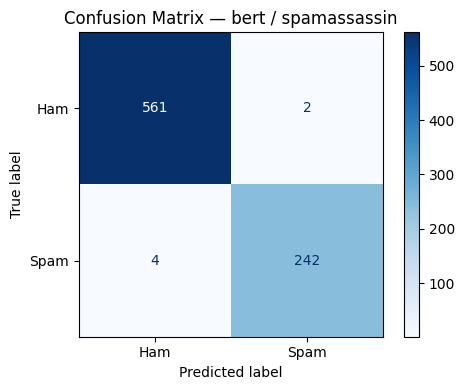

In [13]:
# Load best saved model for test evaluation
best_model = AutoModelForSequenceClassification.from_pretrained(save_dir)
best_model.to(device)

test_metrics = evaluate(best_model, test_loader, device)

print('=' * 50)
print(f'  TEST RESULTS — {ACTIVE_MODEL.upper()} on {ACTIVE_DATASET.upper()}')
print('=' * 50)
for k, v in test_metrics.items():
    if k not in ['preds', 'labels', 'probs']:
        print(f'  {k:12}: {v}')

# Save results
results = {
    'model':        ACTIVE_MODEL,
    'dataset':      ACTIVE_DATASET,
    'best_epoch':   best_epoch,
    'best_val_f1':  best_f1,
    'test_metrics': {k: v for k, v in test_metrics.items() if k not in ['preds','labels','probs']},
    'history':      history,
}
with open(f'{save_dir}/results.json', 'w') as f:
    json.dump(results, f, indent=2)
print(f'\nResults saved to {save_dir}/results.json')

# Confusion matrix
cm = confusion_matrix(test_metrics['labels'], test_metrics['preds'])
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=['Ham', 'Spam']).plot(ax=ax, cmap='Blues')
ax.set_title(f'Confusion Matrix — {ACTIVE_MODEL} / {ACTIVE_DATASET}')
plt.tight_layout()
plt.savefig(f'{save_dir}/confusion_matrix.png', dpi=150)
plt.show()

## Cell 14 Training History Plot
> **Why:** Visualizes the loss and F1 curves over epochs, showing whether the model converged well and whether early stopping fired at the right time.

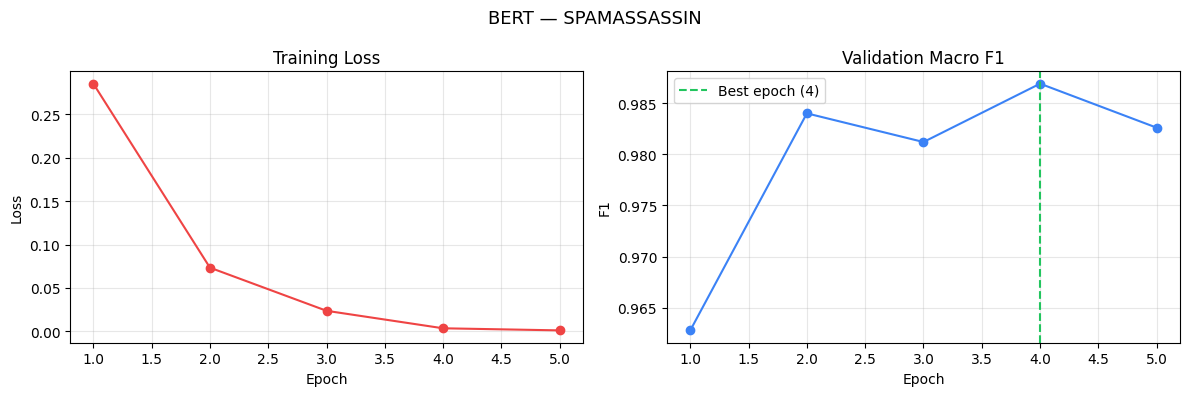

In [14]:
epochs_ran = [h['epoch'] for h in history]
losses     = [h['loss']     for h in history]
f1s        = [h['f1_macro'] for h in history]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs_ran, losses, 'o-', color='#EF4444')
ax1.set_title('Training Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.grid(alpha=0.3)

ax2.plot(epochs_ran, f1s, 'o-', color='#3B82F6')
ax2.axvline(best_epoch, linestyle='--', color='#22C55E', label=f'Best epoch ({best_epoch})')
ax2.set_title('Validation Macro F1')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('F1')
ax2.legend()
ax2.grid(alpha=0.3)

plt.suptitle(f'{ACTIVE_MODEL.upper()} — {ACTIVE_DATASET.upper()}', fontsize=13)
plt.tight_layout()
plt.savefig(f'{save_dir}/training_history.png', dpi=150)
plt.show()

## Cell 15 Classical Baselines (TF-IDF)
> **Why:** Paper Section 5: *"Transformer-based models will be compared to three classical models trained on TF-IDF representations using a vocabulary of 50,000 features: (1) Multinomial Naive Bayes, (2) Linear SVM with L2 regularization, (3) Logistic Regression with L-BFGS optimization."*  
> These baselines establish the performance ceiling of non-contextual methods, making the gains from contextual embeddings directly measurable.

In [15]:
# TF-IDF — 50,000 features as specified in paper
tfidf = TfidfVectorizer(max_features=50_000, sublinear_tf=True)
X_train = tfidf.fit_transform(train_texts)
X_val = tfidf.transform(val_texts)
X_test = tfidf.transform(test_texts)

baselines = {
    'Naive Bayes': MultinomialNB(),
    'Linear SVM (L2)': LinearSVC(C=1.0, max_iter=2000),
    'Logistic Reg (L-BFGS)': LogisticRegression(solver='lbfgs', max_iter=1000, C=1.0),
}

baseline_results = {}

print(f'{"Model":<25} {"Accuracy":>10} {"F1 Macro":>10} {"Precision":>10} {"Recall":>10} {"ROC-AUC":>10}')
print('-' * 78)

for name, clf in baselines.items():
    clf.fit(X_train, train_labels)
    preds = clf.predict(X_test)

    # ROC-AUC from score/probability depending on classifier
    if hasattr(clf, 'predict_proba'):
        scores = clf.predict_proba(X_test)[:, 1]
    else:
        scores = clf.decision_function(X_test)

    metrics = {
        'accuracy': round(accuracy_score(test_labels, preds), 4),
        'f1_macro': round(f1_score(test_labels, preds, average='macro', zero_division=0), 4),
        'precision': round(precision_score(test_labels, preds, average='macro', zero_division=0), 4),
        'recall': round(recall_score(test_labels, preds, average='macro', zero_division=0), 4),
        'roc_auc': round(roc_auc_score(test_labels, scores), 4),
    }
    baseline_results[name] = metrics

    print(
        f'{name:<25} {metrics["accuracy"]:>10} {metrics["f1_macro"]:>10} '
        f'{metrics["precision"]:>10} {metrics["recall"]:>10} {metrics["roc_auc"]:>10}'
    )

print('\n-- Transformer result above for comparison --')
m = test_metrics
print(
    f'{ACTIVE_MODEL.upper():<25} {m["accuracy"]:>10} {m["f1_macro"]:>10} '
    f'{m["precision"]:>10} {m["recall"]:>10} {m["roc_auc"]:>10}'
)

Model                       Accuracy   F1 Macro  Precision     Recall    ROC-AUC
------------------------------------------------------------------------------
Naive Bayes                   0.9333     0.9162     0.9507     0.8937     0.9765
Linear SVM (L2)               0.9926     0.9912     0.9947     0.9878     0.9999
Logistic Reg (L-BFGS)         0.9765     0.9718      0.981     0.9637     0.9962

-- Transformer result above for comparison --
BERT                          0.9926     0.9912     0.9924     0.9901     0.9998


## Cell 16 Ablation: Frozen vs Full Fine-Tuning
> **Why:** Paper Section 5 ablation experiment #1: *"Fine-tuning depth — frozen encoder layers vs fully end-to-end fine-tuning."*  
> This isolates whether the performance gain comes from the pretrained weights alone (frozen) or from adapting the encoder to spam content (full fine-tune).

In [16]:
def quick_train(model, train_loader, val_loader, epochs=2):
    """Quick 2-epoch training run for ablation comparisons."""
    opt   = torch.optim.AdamW(model.parameters(), lr=LR)
    steps = len(train_loader) * epochs
    sch   = get_linear_schedule_with_warmup(opt, int(0.1*steps), steps)

    for ep in range(epochs):
        model.train()
        for batch in train_loader:
            ids  = batch['input_ids'].to(device)
            mask = batch['attention_mask'].to(device)
            lbls = batch['labels'].to(device)
            opt.zero_grad()
            out  = model(input_ids=ids, attention_mask=mask)
            loss = loss_fn(out.logits, lbls)
            loss.backward()
            opt.step(); sch.step()

    return evaluate(model, val_loader, device)

# Frozen encoder
frozen_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)

# Freeze all encoder layers, train only classification head
for name, param in frozen_model.named_parameters():
    if 'classifier' not in name and 'pooler' not in name:
        param.requires_grad = False

frozen_trainable = sum(p.numel() for p in frozen_model.parameters() if p.requires_grad)
print(f'Frozen model trainable params: {frozen_trainable:,}')
frozen_metrics = quick_train(frozen_model, train_loader, val_loader)

# Full fine-tune
full_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)
full_trainable = sum(p.numel() for p in full_model.parameters() if p.requires_grad)
print(f'Full model trainable params  : {full_trainable:,}')
full_metrics = quick_train(full_model, train_loader, val_loader)

print('\n── Ablation: Frozen vs Full Fine-Tuning ──')
print(f'{"Setting":<20} {"F1 Macro":>10} {"Accuracy":>10}')
print('-' * 42)
print(f'{"Frozen encoder":<20} {frozen_metrics["f1_macro"]:>10} {frozen_metrics["accuracy"]:>10}')
print(f'{"Full fine-tune":<20} {full_metrics["f1_macro"]:>10} {full_metrics["accuracy"]:>10}')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Frozen model trainable params: 592,130


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Full model trainable params  : 109,483,778

── Ablation: Frozen vs Full Fine-Tuning ──
Setting                F1 Macro   Accuracy
------------------------------------------
Frozen encoder           0.7944     0.8183
Full fine-tune           0.9855     0.9876


## Cell 17 Ablation: With vs Without Class Weighting
> **Why:** Paper Section 5 ablation experiment #2: *"The effect of class weighting in minority class recall."*  
> This directly measures the impact of the weighted cross-entropy loss on recall — especially on the spam (minority) class. Without weighting, the model may ignore spam to maximize accuracy.

In [17]:
# Without class weighting
loss_fn_unweighted = CrossEntropyLoss()  # no weights

def quick_train_custom_loss(model, loader, val_loader, custom_loss_fn, epochs=2):
    opt = torch.optim.AdamW(model.parameters(), lr=LR)
    steps = len(loader) * epochs
    sch = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)

    for _ in range(epochs):
        model.train()
        for batch in loader:
            ids = batch['input_ids'].to(device)
            mask = batch['attention_mask'].to(device)
            lbls = batch['labels'].to(device)
            opt.zero_grad()
            out = model(input_ids=ids, attention_mask=mask)
            loss = custom_loss_fn(out.logits, lbls)
            loss.backward()
            opt.step()
            sch.step()

    return evaluate(model, val_loader, device)

# No weighting
m_noweight = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)
metrics_noweight = quick_train_custom_loss(m_noweight, train_loader, val_loader, loss_fn_unweighted)

# With weighting (already computed in Cell 8)
m_weighted = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)
metrics_weighted = quick_train_custom_loss(m_weighted, train_loader, val_loader, loss_fn)

print('\n-- Ablation: Class Weighting Impact --')
print(f'{"Setting":<22} {"F1 Macro":>10} {"Recall":>10} {"Spam Recall":>12} {"Precision":>10}')
print('-' * 72)
print(
    f'{"No weighting":<22} {metrics_noweight["f1_macro"]:>10} {metrics_noweight["recall"]:>10} '
    f'{metrics_noweight["spam_recall"]:>12} {metrics_noweight["precision"]:>10}'
)
print(
    f'{"Weighted loss":<22} {metrics_weighted["f1_macro"]:>10} {metrics_weighted["recall"]:>10} '
    f'{metrics_weighted["spam_recall"]:>12} {metrics_weighted["precision"]:>10}'
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



-- Ablation: Class Weighting Impact --
Setting                  F1 Macro     Recall  Spam Recall  Precision
------------------------------------------------------------------------
No weighting               0.9912     0.9912       0.9878     0.9912
Weighted loss              0.9897     0.9881       0.9797     0.9915


In [18]:
class SpamDatasetHeadOnly(Dataset):
    """Ablation dataset: head-only truncation (standard truncation)."""
    def __init__(self, texts, labels, tokenizer, max_len=MAX_LEN):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt',
        )
        return {
            'input_ids':      enc['input_ids'].squeeze(0),
            'attention_mask': enc['attention_mask'].squeeze(0),
            'labels':         torch.tensor(self.labels[idx], dtype=torch.long),
        }

def train_eval_with_dropout(dropout_p, epochs=2):
    # Fix: use model-aware config to set dropout — each model family
    # uses different param names (DistilBERT vs BERT/RoBERTa)
    cfg = AutoConfig.from_pretrained(MODEL_NAME, num_labels=2)
    if 'distilbert' in MODEL_NAME:
        cfg.seq_classif_dropout = dropout_p
        cfg.dropout = dropout_p
    else:  # bert / roberta
        cfg.hidden_dropout_prob = dropout_p
        cfg.attention_probs_dropout_prob = dropout_p
    model_tmp = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, config=cfg
    ).to(device)
    return quick_train_custom_loss(model_tmp, train_loader, val_loader, loss_fn, epochs=epochs)

# Truncation ablation: keep-edges vs head-only
head_only_ds     = SpamDatasetHeadOnly(val_texts, val_labels, tokenizer)
head_only_loader = DataLoader(head_only_ds, batch_size=BATCH_SIZE, shuffle=False)

m_keep_edges = evaluate(best_model, val_loader,     device)
m_head_only  = evaluate(best_model, head_only_loader, device)

print('\n-- Ablation: Truncation Strategy --')
print(f'{"Strategy":<24} {"F1 Macro":>10} {"Accuracy":>10} {"ROC-AUC":>10}')
print('-' * 58)
print(f'{"Keep start+end":<24} {m_keep_edges["f1_macro"]:>10} {m_keep_edges["accuracy"]:>10} {m_keep_edges["roc_auc"]:>10}')
print(f'{"Head-only truncation":<24} {m_head_only["f1_macro"]:>10} {m_head_only["accuracy"]:>10} {m_head_only["roc_auc"]:>10}')

# Dropout ablation: p=0.0 vs p=0.1 vs p=0.3
dropout_results = {}
for p in [0.0, 0.1, 0.3]:
    m = train_eval_with_dropout(dropout_p=p, epochs=2)
    dropout_results[p] = m

print('\n-- Ablation: Dropout Rate Impact --')
print(f'{"Dropout":<10} {"F1 Macro":>10} {"Accuracy":>10} {"ROC-AUC":>10}')
print('-' * 46)
for p in [0.0, 0.1, 0.3]:
    m = dropout_results[p]
    print(f'{p:<10.1f} {m["f1_macro"]:>10} {m["accuracy"]:>10} {m["roc_auc"]:>10}')



-- Ablation: Truncation Strategy --
Strategy                   F1 Macro   Accuracy    ROC-AUC
----------------------------------------------------------
Keep start+end               0.9869     0.9889     0.9984
Head-only truncation         0.9084     0.9209     0.9723


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



-- Ablation: Dropout Rate Impact --
Dropout      F1 Macro   Accuracy    ROC-AUC
----------------------------------------------
0.0            0.9812     0.9839     0.9989
0.1            0.9826     0.9852     0.9992
0.3             0.972     0.9765     0.9888


## Cell 17.1 Ablation: Truncation Strategy and Dropout

> **Why:** Completes the paper's ablation plan by testing (1) truncation strategy impact on long-message classification and (2) dropout impact on cross-corpus robustness.

## Cell 18 Cross-Corpus Generalization (Zero-Shot)
> **Why:** Paper Section 5: *"Models trained on a single corpus will be tested on held-out test sets of the remaining corpora without any further fine-tuning."*  
> This is the zero-shot cross-corpus test — it measures whether learned spam representations generalize across different message domains (corporate email vs academic mailing list vs general spam), which is critical for real-world deployment.

In [19]:
def load_and_tokenize(csv_path, tokenizer, max_len=MAX_LEN):
    if not os.path.exists(csv_path):
        print(f'  Skipping {csv_path} - file not found.')
        return None, None

    # Debug: peek at raw labels before normalization
    df_raw = pd.read_csv(csv_path)
    df_raw.columns = [c.strip().lower() for c in df_raw.columns]
    print(f'\n  [{csv_path}] columns: {list(df_raw.columns)}')
    for col in df_raw.columns:
        if col in {'label', 'spam', 'class', 'category', 'target'}:
            print(f'  Raw label samples: {df_raw[col].unique()[:10]}')

    df_cross = load_dataset(csv_path)
    df_cross['text'] = df_cross['text'].apply(preprocess_text)
    df_cross = df_cross[df_cross['text'].str.len() > 10].reset_index(drop=True)

    # Debug: check label distribution after normalization
    print(f'  Labels after normalization: {df_cross["label"].value_counts().to_dict()}')

    # Skip if only one class survived normalization
    if df_cross['label'].nunique() < 2:
        print(f'  Skipping {csv_path} — only one class found after normalization.')
        return None, None

    texts  = df_cross['text'].tolist()
    labels = df_cross['label'].tolist()

    tr_x, tmp_x, tr_y, tmp_y = train_test_split(
        texts, labels, test_size=0.30, stratify=labels, random_state=42
    )
    _, tst_x, _, tst_y = train_test_split(
        tmp_x, tmp_y, test_size=0.50, stratify=tmp_y, random_state=42
    )

    ds     = SpamDataset(tst_x, tst_y, tokenizer, max_len=max_len)
    loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False)
    return loader, len(tst_x)

# Load best model trained on ACTIVE_DATASET
cross_model = AutoModelForSequenceClassification.from_pretrained(save_dir).to(device)

print(f'Model trained on: {ACTIVE_DATASET}')
print('Testing zero-shot on other corpora (held-out test split only)...\n')
print(f'{"Tested on":<20} {"Samples":>8} {"F1 Macro":>10} {"Accuracy":>10} {"ROC-AUC":>10}')
print('-' * 62)

for corpus_name, corpus_path in DATASET_PATHS.items():
    if corpus_name == ACTIVE_DATASET:
        continue

    loader, n = load_and_tokenize(corpus_path, tokenizer)
    if loader is None:
        continue

    m = evaluate(cross_model, loader, device)
    print(f'{corpus_name:<20} {n:>8} {m["f1_macro"]:>10} {m["accuracy"]:>10} {m["roc_auc"]:>10}')

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model trained on: spamassassin
Testing zero-shot on other corpora (held-out test split only)...

Tested on             Samples   F1 Macro   Accuracy    ROC-AUC
--------------------------------------------------------------

  [data/enron.csv] columns: ['unnamed: 0', 'subject', 'message', 'spam/ham', 'date']
  Labels after normalization: {1: 17171, 0: 16465}
enron                    5046     0.3005     0.3072     0.3575

  [data/lingspam.csv] columns: ['subject', 'message', 'label']
  Raw label samples: [0 1]
  Labels after normalization: {0: 2412, 1: 477}
lingspam                  434     0.6259     0.6682     0.9792


## Cell 19 Full Comparison Table
> **Why:** Produces the final summary table comparing all three transformer models against all three classical baselines — the core result table of the paper.

In [20]:
# Collect all results for the summary table
# (Run Cells 12-15 for each model, then fill this dict)

# Transformer results (fill in after running each model)
transformer_results = {
    ACTIVE_MODEL: {
        k: v for k, v in test_metrics.items()
        if k not in ['preds', 'labels', 'probs']
    }
    # Add other model results here after training them:
    # 'bert': {...},
    # 'roberta': {...},
}

# Build comparison DataFrame
rows = []
for name, m in baseline_results.items():
    rows.append({'Model': f'[Baseline] {name}', **m})
for name, m in transformer_results.items():
    rows.append({'Model': f'[Transformer] {name.upper()}', **m})

comparison_df = pd.DataFrame(rows).set_index('Model')

# Keep a consistent column order if available
ordered_cols = ['accuracy', 'f1_macro', 'precision', 'recall', 'roc_auc']
comparison_df = comparison_df[[c for c in ordered_cols if c in comparison_df.columns]]
comparison_df.columns = ['Accuracy', 'F1 Macro', 'Precision', 'Recall', 'ROC-AUC']

print(f'\n--- Results on {ACTIVE_DATASET.upper()} dataset ---')
print(comparison_df.to_string())

# Save to CSV
comparison_df.to_csv(f'{save_dir}/comparison_table.csv')
print(f'\nSaved to {save_dir}/comparison_table.csv')


--- Results on SPAMASSASSIN dataset ---
                                  Accuracy  F1 Macro  Precision  Recall  ROC-AUC
Model                                                                           
[Baseline] Naive Bayes              0.9333    0.9162     0.9507  0.8937   0.9765
[Baseline] Linear SVM (L2)          0.9926    0.9912     0.9947  0.9878   0.9999
[Baseline] Logistic Reg (L-BFGS)    0.9765    0.9718     0.9810  0.9637   0.9962
[Transformer] BERT                  0.9926    0.9912     0.9924  0.9901   0.9998

Saved to models/bert_spamassassin/comparison_table.csv


## Cell 20 Quick Inference (Test a Single Message)
> **Why:** Validates the trained model works end-to-end and serves as the inference function wired to the Flet UI backend.

In [21]:
def predict(text, model, tokenizer, device):
    """
    Single-message inference — used by the Flet UI backend.
    Returns label, spam probability, ham probability, confidence.

    FIX 2 (Paper Section 3): Apply the same sliding-window truncation used
    during training (_truncate_keep_edges). The original predict() used plain
    head-only truncation (truncation=True), which mismatches the training
    distribution — long ham messages lose their tail content and look more
    like spam. Both training and inference must use the same strategy.
    """
    model.eval()
    text = preprocess_text(text)

    # Match the training truncation strategy (Paper Section 3: keep start + end)
    tokens = tokenizer.encode(text, add_special_tokens=False, truncation=False)
    max_tokens = MAX_LEN - 2  # reserve slots for [CLS] / [SEP]
    if len(tokens) > max_tokens:
        half = max_tokens // 2
        tokens = tokens[:half] + tokens[-(max_tokens - half):]
        text = tokenizer.decode(tokens, skip_special_tokens=True)

    inputs = tokenizer(
        text,
        return_tensors='pt',
        max_length=MAX_LEN,
        truncation=True,   # safety net after manual edge truncation
        padding=True,
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        out = model(**inputs)

    probs     = torch.softmax(out.logits, dim=1)[0]
    ham_prob  = probs[0].item()
    spam_prob = probs[1].item()
    is_spam   = spam_prob > 0.5

    return {
        'label':      'SPAM' if is_spam else 'HAM',
        'is_spam':    is_spam,
        'spam_prob':  round(spam_prob, 4),
        'ham_prob':   round(ham_prob, 4),
        'confidence': round(max(spam_prob, ham_prob), 4),
    }

# Test examples
test_messages = [
    'CONGRATULATIONS! You have been selected for a FREE iPhone. Click NOW to claim!!!',
    'Hi team, the meeting tomorrow is moved to 3pm. Please update your calendars.',
    'URGENT: Your bank account has been compromised. Verify immediately or it will be closed.',
]

inference_model = AutoModelForSequenceClassification.from_pretrained(save_dir).to(device)

print('─── Inference Demo ───\n')
for msg in test_messages:
    result = predict(msg, inference_model, tokenizer, device)
    icon   = '🚨' if result['is_spam'] else '✅'
    print(f'{icon} {result["label"]}  (spam={result["spam_prob"]:.2%}  conf={result["confidence"]:.2%})')
    print(f'   {msg[:80]}...')
    print()


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

─── Inference Demo ───

🚨 SPAM  (spam=99.98%  conf=99.98%)
   CONGRATULATIONS! You have been selected for a FREE iPhone. Click NOW to claim!!!...

🚨 SPAM  (spam=99.97%  conf=99.97%)
   Hi team, the meeting tomorrow is moved to 3pm. Please update your calendars....

🚨 SPAM  (spam=99.96%  conf=99.96%)
   URGENT: Your bank account has been compromised. Verify immediately or it will be...

